# 03. Evaluate an Elo-only logistic baseline

Ask whether logistic regression improves the probabilities implied by global Elo. Read notebook 02's pre-match features, train on the earliest period, inspect validation, then refit on training plus validation before evaluating the final period.

Split at 60% and 80% of distinct timestamps, keeping simultaneous games together. Elo state remains adaptive through evaluation, while logistic coefficients stay fixed within each evaluation period. The existing test period has already influenced development; later final claims require an untouched period.


## 01. Locate features and import modeling tools

Import logistic regression, scaling, metrics, plotting, and model persistence tools. Require `elo_features_all_years.csv` from notebook 02. This baseline uses only global Elo difference as its predictive feature.


In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    log_loss,
    roc_auc_score,
)

base = Path.cwd()

if not (base / "data" / "processed").is_dir():
    base = base.parent

input_path = (
    base / "data" / "processed" / "elo_features_all_years.csv"
)

if not input_path.is_file():
    raise FileNotFoundError(
        f"Missing {input_path}. Run notebook 02 first."
    )

## 02. Validate the modeling table

Read identities, outcomes, Elo differences, and probabilities. Check completeness, unique IDs, binary results, finite features, and valid probability bounds. Parse UTC dates and sort chronologically before splitting.


In [2]:
features = pd.read_csv(
    input_path,
    dtype={"match_id": "string"},
)

required_columns = [
    "match_id",
    "date",
    "league",
    "team_a",
    "team_b",
    "result_a",
    "elo_diff",
    "elo_probability_a",
]

missing_columns = set(required_columns) - set(features.columns)

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

features["date"] = pd.to_datetime(
    features["date"],
    utc=True,
    errors="raise",
    format="mixed",
)

if features.empty:
    raise ValueError("The feature table is empty.")

if features[required_columns].isna().any().any():
    raise ValueError("Missing values found in required columns.")

if not features["match_id"].is_unique:
    raise ValueError("Duplicate match IDs found.")

if not features["result_a"].isin([0, 1]).all():
    raise ValueError("Results must be 0 or 1.")

numeric_columns = ["elo_diff", "elo_probability_a"]

if not np.isfinite(features[numeric_columns].to_numpy(float)).all():
    raise ValueError("Nonfinite feature values found.")

if not features["elo_probability_a"].between(0, 1).all():
    raise ValueError("Elo probabilities must be between 0 and 1.")

features = (
    features.sort_values(["date", "match_id"])
    .reset_index(drop=True)
)

features["result_a"] = features["result_a"].astype("int64")

print("Matches:", len(features))
display(features.head())

Matches: 96075


,match_id,date,league,team_a,team_b,result_a,pre_elo_a,pre_elo_b,elo_diff,elo_probability_a
0,2017-01-10 15:44:06+00:00|EU CS|TREU/1001490056,2017-01-10 15:44:06+00:00,EU CS,EURONICS Gaming,Fnatic Academy,0,1500.0,1500.0,0.0,0.5
1,2017-01-10 16:21:23+00:00|EU CS|TREU/1001490066,2017-01-10 16:21:23+00:00,EU CS,AlienTech eSports,Team Larssen,0,1500.0,1500.0,0.0,0.5
2,2017-01-10 17:01:50+00:00|EU CS|TREU/1001490072,2017-01-10 17:01:50+00:00,EU CS,Bobaski,Nerv,0,1500.0,1500.0,0.0,0.5
3,2017-01-10 17:55:36+00:00|EU CS|TREU/1001490081,2017-01-10 17:55:36+00:00,EU CS,Team Forge,Tricked Esport,1,1500.0,1500.0,0.0,0.5
4,2017-01-10 18:57:51+00:00|EU CS|TREU/1001490084,2017-01-10 18:57:51+00:00,EU CS,ASUS ROG Army,LDLC OL,0,1500.0,1500.0,0.0,0.5


## 03. Split by distinct timestamps

Use timestamps at the 60% and 80% positions as validation and test starts. Every equal-timestamp group stays in one period, so match counts need not be exactly 60/20/20. Verify strict temporal separation and record observed starts, ends, and counts.


In [3]:
timestamps = (
    features["date"]
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

if len(timestamps) < 10:
    raise ValueError("Too few distinct timestamps for this split.")

validation_start = timestamps.iloc[int(len(timestamps) * 0.60)]
test_start = timestamps.iloc[int(len(timestamps) * 0.80)]

train = features.loc[
    features["date"] < validation_start
].copy()

validation = features.loc[
    features["date"].ge(validation_start)
    & features["date"].lt(test_start)
].copy()

test = features.loc[
    features["date"].ge(test_start)
].copy()

for name, frame in [
    ("training", train),
    ("validation", validation),
    ("testing", test),
]:
    if frame.empty:
        raise ValueError(f"The {name} split is empty.")

assert train["date"].max() < validation["date"].min()
assert validation["date"].max() < test["date"].min()

split_summary = pd.DataFrame(
    [
        {
            "split": name,
            "matches": len(frame),
            "start": frame["date"].min(),
            "end": frame["date"].max(),
        }
        for name, frame in [
            ("training", train),
            ("validation", validation),
            ("testing", test),
        ]
    ]
)

display(split_summary)

,split,matches,start,end
0,training,57656,2017-01-10 15:44:06+00:00,2023-03-04 22:15:44+00:00
1,validation,19215,2023-03-04 22:51:24+00:00,2025-02-05 18:49:52+00:00
2,testing,19204,2025-02-05 18:58:03+00:00,2026-10-26 21:54:37+00:00


## 04. Define symmetric logistic regression

Train on `elo_diff` plus a mirrored copy with negated difference and complementary result. Fit `StandardScaler(with_mean=False)` inside the training pipeline, followed by logistic regression with C=1 and no intercept. The probability is `sigmoid(beta * scaled_elo_diff)`; this setup preserves opponent symmetry and gives 0.5 at zero difference.


In [4]:
FEATURE_COLUMNS = ["elo_diff"]


def fit_logistic_model(frame):
    x = frame[FEATURE_COLUMNS].to_numpy(dtype=float)
    y = frame["result_a"].to_numpy(dtype=int)

    mirrored_x = np.concatenate([x, -x], axis=0)
    mirrored_y = np.concatenate([y, 1 - y], axis=0)

    model = make_pipeline(
        StandardScaler(with_mean=False),
        LogisticRegression(
            C=1.0,
            fit_intercept=False,
            max_iter=1000,
        ),
    )

    model.fit(mirrored_x, mirrored_y)

    return model

## 05. Define probability evaluation metrics

Accuracy uses a 0.5 threshold. Log loss penalizes confident errors; Brier score measures squared probability error, with lower better for both. ROC AUC measures ranking, with higher better, and is undefined with only one outcome class. Always read scores with their match counts.


In [5]:
def evaluate_probabilities(results, probabilities):
    y = np.asarray(results, dtype=int)
    p = np.asarray(probabilities, dtype=float)

    if len(y) == 0:
        raise ValueError("Cannot evaluate an empty dataset.")

    if len(y) != len(p):
        raise ValueError("Results and probabilities have different lengths.")

    if not np.isfinite(p).all() or ((p < 0) | (p > 1)).any():
        raise ValueError("Invalid probabilities.")

    # Protect logarithms from exact zero or one.
    p = np.clip(p, 1e-12, 1 - 1e-12)

    return {
        "matches": len(y),
        "accuracy": accuracy_score(y, p >= 0.5),
        "log_loss": log_loss(y, p, labels=[0, 1]),
        "brier": brier_score_loss(y, p),
        "roc_auc": (
            roc_auc_score(y, p)
            if len(np.unique(y)) == 2
            else np.nan
        ),
    }

## 06. Fit training and inspect validation

Fit scaling and logistic coefficients on training only, then compare validation predictions with raw global Elo on the same matches. Different log loss with identical accuracy means confidence changed without changing winner choices. Validation is the earlier assessment before final refitting.


In [6]:
validation_model = fit_logistic_model(train)

validation_probabilities = validation_model.predict_proba(
    validation[FEATURE_COLUMNS].to_numpy(dtype=float)
)[:, 1]

validation_report = pd.DataFrame(
    {
        "global_elo": evaluate_probabilities(
            validation["result_a"],
            validation["elo_probability_a"],
        ),
        "elo_logistic": evaluate_probabilities(
            validation["result_a"],
            validation_probabilities,
        ),
    }
).T

display(validation_report)

,matches,accuracy,log_loss,brier,roc_auc
global_elo,19215.0,0.629872,0.640070,0.224808,0.680932
elo_logistic,19215.0,0.629872,0.639764,0.224713,0.680932


## 07. Refit on training plus validation

Combine the development periods and refit without test labels. Synthetic differences check that swapping opponents complements the probability and a zero difference gives 0.5. Keep this refitted model fixed throughout test evaluation.


In [7]:
development = pd.concat(
    [train, validation],
    ignore_index=True,
).sort_values(["date", "match_id"])

assert development["date"].max() < test["date"].min()

final_model = fit_logistic_model(development)

# Check opponent symmetry.
example_differences = np.array(
    [[-200.0], [0.0], [200.0]]
)

forward_probabilities = final_model.predict_proba(
    example_differences
)[:, 1]

reverse_probabilities = final_model.predict_proba(
    -example_differences
)[:, 1]

np.testing.assert_allclose(
    forward_probabilities + reverse_probabilities,
    1.0,
)

assert np.isclose(forward_probabilities[1], 0.5)

print("Model symmetry checks passed.")

Model symmetry checks passed.


## 08. Evaluate the final period

Predict every test game and compare both probability methods on identical results. Earlier test outcomes have already updated upstream Elo features used by later games. This online evaluation is different from forecasting an entire tournament before it begins.


In [8]:
test_predictions = test.copy()

test_predictions["logistic_probability_a"] = (
    final_model.predict_proba(
        test_predictions[FEATURE_COLUMNS].to_numpy(dtype=float)
    )[:, 1]
)

test_report = pd.DataFrame(
    {
        "global_elo": evaluate_probabilities(
            test_predictions["result_a"],
            test_predictions["elo_probability_a"],
        ),
        "elo_logistic": evaluate_probabilities(
            test_predictions["result_a"],
            test_predictions["logistic_probability_a"],
        ),
    }
).T

display(test_report)

,matches,accuracy,log_loss,brier,roc_auc
global_elo,19204.0,0.630077,0.640541,0.224841,0.681242
elo_logistic,19204.0,0.630077,0.640172,0.224736,0.681242


## 09. Compare competition scopes

Report all games, MSI plus WLDs, and WLDs separately using source league labels. Small international samples can fluctuate more than the all-game sample. These labels are not independently verified competition identities.


In [9]:
scope_masks = {
    "all": pd.Series(True, index=test_predictions.index),
    "msi_and_worlds": test_predictions["league"].isin(
        ["MSI", "WLDs"]
    ),
    "worlds": test_predictions["league"].eq("WLDs"),
}

scope_rows = []

for scope, mask in scope_masks.items():
    group = test_predictions.loc[mask]

    if group.empty:
        print(f"No test matches for scope: {scope}")
        continue

    for model_name, probability_column in [
        ("global_elo", "elo_probability_a"),
        ("elo_logistic", "logistic_probability_a"),
    ]:
        scope_rows.append(
            {
                "scope": scope,
                "model": model_name,
                **evaluate_probabilities(
                    group["result_a"],
                    group[probability_column],
                ),
            }
        )

scope_report = pd.DataFrame(scope_rows)

display(scope_report)

,scope,model,matches,accuracy,log_loss,brier,roc_auc
0,all,global_elo,19204,0.630077,0.640541,0.224841,0.681242
1,all,elo_logistic,19204,0.630077,0.640172,0.224736,0.681242
2,msi_and_worlds,global_elo,310,0.590323,0.662907,0.236111,0.619237
3,msi_and_worlds,elo_logistic,310,0.590323,0.662637,0.235873,0.619237
4,worlds,global_elo,159,0.578616,0.673760,0.240903,0.603180
5,worlds,elo_logistic,159,0.578616,0.673131,0.240555,0.603180


## 10. Inspect probability calibration

Group probabilities into ten fixed-width bins and compare average predicted probability with observed win rate. Points near the diagonal indicate agreement between confidence and frequency. Inspect bin counts because sparsely populated bins are uncertain.


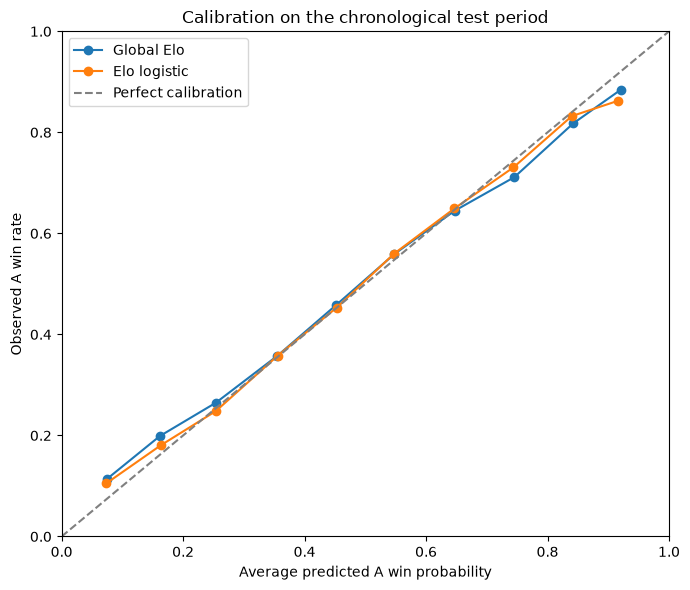

Global Elo


,probability_bin,predicted_probability,observed_win_rate,matches
0,"(-0.001, 0.1]",0.075411,0.114583,96
1,"(0.1, 0.2]",0.161783,0.198856,699
2,"(0.2, 0.3]",0.253852,0.264706,1564
3,"(0.3, 0.4]",0.355259,0.357735,2896
4,"(0.4, 0.5]",0.452372,0.458626,4278
5,"(0.5, 0.6]",0.547835,0.559087,4248
6,"(0.6, 0.7]",0.647422,0.645039,2913
7,"(0.7, 0.8]",0.745366,0.711322,1687
8,"(0.8, 0.9]",0.842216,0.817664,702
9,"(0.9, 1.0]",0.920440,0.884298,121


Elo logistic


,probability_bin,predicted_probability,observed_win_rate,matches
0,"(-0.001, 0.1]",0.073691,0.105263,57
1,"(0.1, 0.2]",0.162898,0.180243,577
2,"(0.2, 0.3]",0.254141,0.248485,1485
3,"(0.3, 0.4]",0.355836,0.358080,2896
4,"(0.4, 0.5]",0.452581,0.452855,4518
5,"(0.5, 0.6]",0.547370,0.559785,4466
6,"(0.6, 0.7]",0.646603,0.649289,2954
7,"(0.7, 0.8]",0.743861,0.730646,1563
8,"(0.8, 0.9]",0.840051,0.832237,608
9,"(0.9, 1.0]",0.916095,0.862500,80


In [10]:
calibration_tables = {}

fig, ax = plt.subplots(figsize=(7, 6))

for model_name, probability_column in [
    ("Global Elo", "elo_probability_a"),
    ("Elo logistic", "logistic_probability_a"),
]:
    frame = test_predictions[
        ["result_a", probability_column]
    ].copy()

    frame["probability_bin"] = pd.cut(
        frame[probability_column],
        bins=np.linspace(0, 1, 11),
        include_lowest=True,
    )

    calibration = (
        frame.groupby("probability_bin", observed=True)
        .agg(
            predicted_probability=(probability_column, "mean"),
            observed_win_rate=("result_a", "mean"),
            matches=("result_a", "size"),
        )
        .reset_index()
    )

    calibration_tables[model_name] = calibration

    ax.plot(
        calibration["predicted_probability"],
        calibration["observed_win_rate"],
        marker="o",
        label=model_name,
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect calibration",
)

ax.set(
    xlabel="Average predicted A win probability",
    ylabel="Observed A win rate",
    title="Calibration on the chronological test period",
    xlim=(0, 1),
    ylim=(0, 1),
)

ax.legend()
plt.tight_layout()
plt.show()

for model_name, table in calibration_tables.items():
    print(model_name)
    display(table)

## 11. Save the model and evaluation record

Persist the pipeline with feature names, training cutoff, exact split starts, training count, and settings. Export predictions, metrics, scope summaries, and calibration tables to `results/baseline/`. Notebooks 04 and 06 reuse these boundaries to keep comparisons aligned.


In [11]:
model_dir = base / "models"
results_dir = base / "results" / "baseline"

model_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

model_bundle = {
    "model": final_model,
    "feature_columns": FEATURE_COLUMNS,
    "trained_through": development["date"].max().isoformat(),
    "validation_start": validation_start.isoformat(),
    "test_start": test_start.isoformat(),
    "training_rows": len(development),
    "mirrored_training": True,
    "settings": {
        "C": 1.0,
        "fit_intercept": False,
    },
}

model_path = model_dir / "elo_logistic_baseline.joblib"

joblib.dump(model_bundle, model_path)

split_summary.to_csv(
    results_dir / "chronological_splits.csv",
    index=False,
)

validation_report.to_csv(
    results_dir / "validation_metrics.csv",
    index=True,
)

test_report.to_csv(
    results_dir / "test_metrics.csv",
    index=True,
)

scope_report.to_csv(
    results_dir / "test_metrics_by_scope.csv",
    index=False,
)

test_predictions.to_csv(
    results_dir / "test_predictions.csv",
    index=False,
)

for model_name, table in calibration_tables.items():
    filename = model_name.lower().replace(" ", "_")

    table.to_csv(
        results_dir / f"calibration_{filename}.csv",
        index=False,
    )

print("Saved model:", model_path)
print("Saved evaluation:", results_dir)
print("Model trained through:", model_bundle["trained_through"])

Saved model: C:\Users\USER\lol_worlds_predictor\models\elo_logistic_baseline.joblib
Saved evaluation: C:\Users\USER\lol_worlds_predictor\results\baseline
Model trained through: 2025-02-05T18:49:52+00:00
